# **SmartCropAdvisor: Model Development and Evaluation**

Author: `Rozhak`  
Version: 1.1.0  
Tujuan: *Membandingkan kandidat model klasifikasi tanaman menggunakan Stratified 5-Fold Cross-Validation, mengevaluasi model terbaik pada held-out test set, serta mengekspor pipeline dan metadata untuk Streamlit UI.*

## **1. Pendahuluan**

Notebook ini membandingkan tiga model klasifikasi (`GaussianNB` sebagai baseline, `RandomForestClassifier`, dan `MLPClassifier`) untuk memprediksi jenis tanaman dari 7 parameter tanah dan iklim. Karena fitur `P` dan `K` memiliki korelasi cukup tinggi (`0.74`) dan sebaran beberapa fitur bersifat multimodal, `RandomForestClassifier` diperkirakan mampu memberi performa `f1_macro` yang tinggi dan stabil antar-fold tanpa bergantung pada asumsi independensi fitur.

Untuk mencegah *data leakage*, dataset dibagi 80/20 secara *stratified* (`random_state=42`) di awal. Seluruh perbandingan dan pemilihan model dilakukan menggunakan Stratified 5-Fold Cross-Validation pada *training set*, sedangkan *test set* hanya digunakan sekali di akhir untuk mengevaluasi model terpilih.

## **2. Konfigurasi dan Logging**

Memuat parameter eksperimen dari `config/settings.yaml` ke `ExperimentConfig` dan menyiapkan `log_event` berformat key-value.

In [1]:
from dataclasses import dataclass
from datetime import datetime, timezone
import json
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import yaml

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display


def log_event(category: str, **kwargs: Any) -> None:
    details = " | ".join(f"{k}={v}" for k, v in kwargs.items())
    print(f"[{category.upper()}] {details}")


@dataclass(frozen=True)
class ExperimentConfig:
    project_name: str
    version: str
    random_state: int
    raw_path: Path
    target_column: str
    feature_columns: list[str]
    test_size: float
    stratify: bool
    cv_folds: int
    primary_metric: str
    secondary_metric: str
    artifacts_dir: Path
    plots_dir: Path
    model_path: Path
    metadata_path: Path
    models_cfg: dict[str, dict[str, Any]]


def load_experiment_config(config_path: Path) -> ExperimentConfig:
    if not config_path.exists():
        raise FileNotFoundError(f"Config file not found: {config_path}")

    with config_path.open("r", encoding="utf-8") as file:
        raw = yaml.safe_load(file)

    base_dir = config_path.parent.parent
    artifacts_dir = base_dir / raw["artifacts"]["dir"]
    plots_dir = base_dir / raw["artifacts"]["eval_plots_dir"]
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    plots_dir.mkdir(parents=True, exist_ok=True)

    cfg = ExperimentConfig(
        project_name=raw["project"]["name"],
        version=raw["project"]["version"],
        random_state=int(raw["project"]["random_state"]),
        raw_path=base_dir / raw["data"]["raw_path"],
        target_column=raw["data"]["target_column"],
        feature_columns=list(raw["data"]["feature_columns"]),
        test_size=float(raw["split"]["test_size"]),
        stratify=bool(raw["split"]["stratify"]),
        cv_folds=int(raw["evaluation"]["cv_folds"]),
        primary_metric=raw["evaluation"]["primary_metric"],
        secondary_metric=raw["evaluation"]["secondary_metric"],
        artifacts_dir=artifacts_dir,
        plots_dir=plots_dir,
        model_path=artifacts_dir / raw["artifacts"]["model_filename"],
        metadata_path=artifacts_dir / raw["artifacts"]["metadata_filename"],
        models_cfg=raw["models"],
    )
    log_event(
        "CONFIG",
        status="LOADED",
        cv_folds=cfg.cv_folds,
        primary_metric=cfg.primary_metric,
        plots_dir=cfg.plots_dir.as_posix(),
    )
    return cfg


config = load_experiment_config(Path("config/settings.yaml"))

[CONFIG] status=LOADED | cv_folds=5 | primary_metric=f1_macro | plots_dir=artifacts/plots/eval


## **3. Pipeline Preprocessing dan Runner Eksperimen**

Menggabungkan `StandardScaler` dan estimator dalam satu `sklearn.pipeline.Pipeline` agar transformasi fitur saat *training* dan *serving* tetap konsisten.

### **3.1 Registry Model dan Builder Pipeline**

Memetakan nama estimator dari `settings.yaml` ke kelas scikit-learn terkait lalu menyatukannya bersama `StandardScaler` di dalam `Pipeline`.

In [2]:
MODEL_REGISTRY: dict[str, type] = {
    "GaussianNB": GaussianNB,
    "RandomForestClassifier": RandomForestClassifier,
    "MLPClassifier": MLPClassifier,
}


def build_pipeline(model_name: str, params: dict[str, Any]) -> Pipeline:
    if model_name not in MODEL_REGISTRY:
        raise ValueError(f"Unsupported model: {model_name}")

    normalized_params = dict(params)
    if "hidden_layer_sizes" in normalized_params:
        normalized_params["hidden_layer_sizes"] = tuple(normalized_params["hidden_layer_sizes"])

    estimator = MODEL_REGISTRY[model_name](**normalized_params)
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("classifier", estimator),
        ]
    )

### **3.2 Kelas ExperimentRunner**

Menjalankan *split* 80/20, iterasi Stratified 5-Fold CV, pemilihan model terbaik berdasarkan `f1_macro`, serta evaluasi akhir pada *test set*.

In [3]:
@dataclass
class ExperimentResult:
    comparison_df: pd.DataFrame
    winner_name: str
    winner_pipeline: Pipeline
    winner_cv_metrics: dict[str, float]
    test_accuracy: float
    test_f1_macro: float
    classification_report_df: pd.DataFrame
    y_test: pd.Series
    y_pred: np.ndarray
    X_full: pd.DataFrame
    y_full: pd.Series


class ExperimentRunner:
    def __init__(self, cfg: ExperimentConfig) -> None:
        self.cfg = cfg

    def run(self) -> ExperimentResult:
        df = pd.read_csv(self.cfg.raw_path)
        X = df[self.cfg.feature_columns]
        y = df[self.cfg.target_column]

        stratify_target = y if self.cfg.stratify else None
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=self.cfg.test_size,
            random_state=self.cfg.random_state,
            stratify=stratify_target,
        )
        log_event("DATA_SPLIT", train_rows=X_train.shape[0], test_rows=X_test.shape[0], stratified=self.cfg.stratify)

        cv = StratifiedKFold(n_splits=self.cfg.cv_folds, shuffle=True, random_state=self.cfg.random_state)
        scoring = {
            "f1_macro": "f1_macro",
            "accuracy": "accuracy",
        }

        records: list[dict[str, Any]] = []
        for model_name, model_spec in self.cfg.models_cfg.items():
            if not model_spec.get("enabled", True):
                continue

            pipeline = build_pipeline(model_name, model_spec.get("params", {}))
            log_event("CV_RUN", status="STARTED", model=model_name, folds=self.cfg.cv_folds)
            cv_out = cross_validate(
                pipeline,
                X_train,
                y_train,
                cv=cv,
                scoring=scoring,
                n_jobs=1,
            )
            f1_mean = float(np.mean(cv_out["test_f1_macro"]))
            f1_std = float(np.std(cv_out["test_f1_macro"]))
            acc_mean = float(np.mean(cv_out["test_accuracy"]))
            acc_std = float(np.std(cv_out["test_accuracy"]))

            records.append(
                {
                    "model": model_name,
                    "cv_f1_macro_mean": round(f1_mean, 5),
                    "cv_f1_macro_std": round(f1_std, 5),
                    "cv_accuracy_mean": round(acc_mean, 5),
                    "cv_accuracy_std": round(acc_std, 5),
                }
            )
            log_event(
                "CV_RUN",
                status="COMPLETED",
                model=model_name,
                f1_macro=f"{f1_mean:.4f}",
                f1_std=f"{f1_std:.4f}",
                accuracy=f"{acc_mean:.4f}",
            )

        comparison_df = pd.DataFrame(records).sort_values(
            by=["cv_f1_macro_mean", "cv_f1_macro_std"],
            ascending=[False, True],
        ).reset_index(drop=True)

        winner_row = comparison_df.iloc[0]
        winner_name = str(winner_row["model"])
        winner_params = self.cfg.models_cfg[winner_name].get("params", {})
        winner_pipeline = build_pipeline(winner_name, winner_params)
        winner_pipeline.fit(X_train, y_train)

        y_pred = winner_pipeline.predict(X_test)
        test_acc = float(accuracy_score(y_test, y_pred))
        test_f1 = float(f1_score(y_test, y_pred, average="macro"))
        report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
        report_df = pd.DataFrame(report_dict).transpose().round(4)

        log_event(
            "TEST_EVAL",
            winner=winner_name,
            test_accuracy=f"{test_acc:.4f}",
            test_f1_macro=f"{test_f1:.4f}",
        )

        return ExperimentResult(
            comparison_df=comparison_df,
            winner_name=winner_name,
            winner_pipeline=winner_pipeline,
            winner_cv_metrics={
                "cv_mean": float(winner_row["cv_f1_macro_mean"]),
                "cv_std": float(winner_row["cv_f1_macro_std"]),
                "cv_accuracy_mean": float(winner_row["cv_accuracy_mean"]),
            },
            test_accuracy=test_acc,
            test_f1_macro=test_f1,
            classification_report_df=report_df,
            y_test=y_test,
            y_pred=y_pred,
            X_full=X,
            y_full=y,
        )

## **4. Eksekusi Training dan Evaluasi**

Menjalankan eksperimen pada seluruh kandidat model dan menampilkan hasil komparasi serta evaluasi model terpilih.

### **4.1 Perbandingan Skor Cross-Validation**

Tabel rata-rata dan standar deviasi `f1_macro` serta `accuracy` dari 5 fold pada *training set*.

In [4]:
runner = ExperimentRunner(config)
result = runner.run()
display(result.comparison_df)

[DATA_SPLIT] train_rows=1760 | test_rows=440 | stratified=True
[CV_RUN] status=STARTED | model=GaussianNB | folds=5
[CV_RUN] status=COMPLETED | model=GaussianNB | f1_macro=0.9949 | f1_std=0.0042 | accuracy=0.9949
[CV_RUN] status=STARTED | model=RandomForestClassifier | folds=5
[CV_RUN] status=COMPLETED | model=RandomForestClassifier | f1_macro=0.9926 | f1_std=0.0059 | accuracy=0.9926
[CV_RUN] status=STARTED | model=MLPClassifier | folds=5
[CV_RUN] status=COMPLETED | model=MLPClassifier | f1_macro=0.9846 | f1_std=0.0054 | accuracy=0.9847
[TEST_EVAL] winner=GaussianNB | test_accuracy=0.9955 | test_f1_macro=0.9954


,model,cv_f1_macro_mean,cv_f1_macro_std,cv_accuracy_mean,cv_accuracy_std
0,GaussianNB,0.99487,0.00419,0.99489,0.00418
1,RandomForestClassifier,0.99257,0.00592,0.99261,0.00585
2,MLPClassifier,0.98457,0.00536,0.98466,0.00527


### **4.2 Evaluasi Model Terpilih pada Test Set**

Laporan *precision*, *recall*, dan *f1-score* per kelas tanaman pada *held-out test set*.

In [5]:
log_event("FINAL_REPORT", model=result.winner_name, accuracy=round(result.test_accuracy, 4), f1_macro=round(result.test_f1_macro, 4))
display(result.classification_report_df)

[FINAL_REPORT] model=GaussianNB | accuracy=0.9955 | f1_macro=0.9954


,precision,recall,f1-score,support
apple,1.0000,1.0000,1.0000,20.0000
banana,1.0000,1.0000,1.0000,20.0000
blackgram,1.0000,1.0000,1.0000,20.0000
chickpea,1.0000,1.0000,1.0000,20.0000
coconut,1.0000,1.0000,1.0000,20.0000
coffee,1.0000,1.0000,1.0000,20.0000
cotton,1.0000,1.0000,1.0000,20.0000
grapes,1.0000,1.0000,1.0000,20.0000
jute,0.9091,1.0000,0.9524,20.0000
kidneybeans,1.0000,1.0000,1.0000,20.0000


## **5. Visualisasi Evaluasi Model**

Menyimpan grafik perbandingan skor CV, *confusion matrix*, dan *feature importance* ke `artifacts/plots/eval/`.

### **5.1 Perbandingan Skor Cross-Validation**

Grafik batang rata-rata `f1_macro` beserta *error bar* standar deviasi untuk menilai stabilitas tiap model.

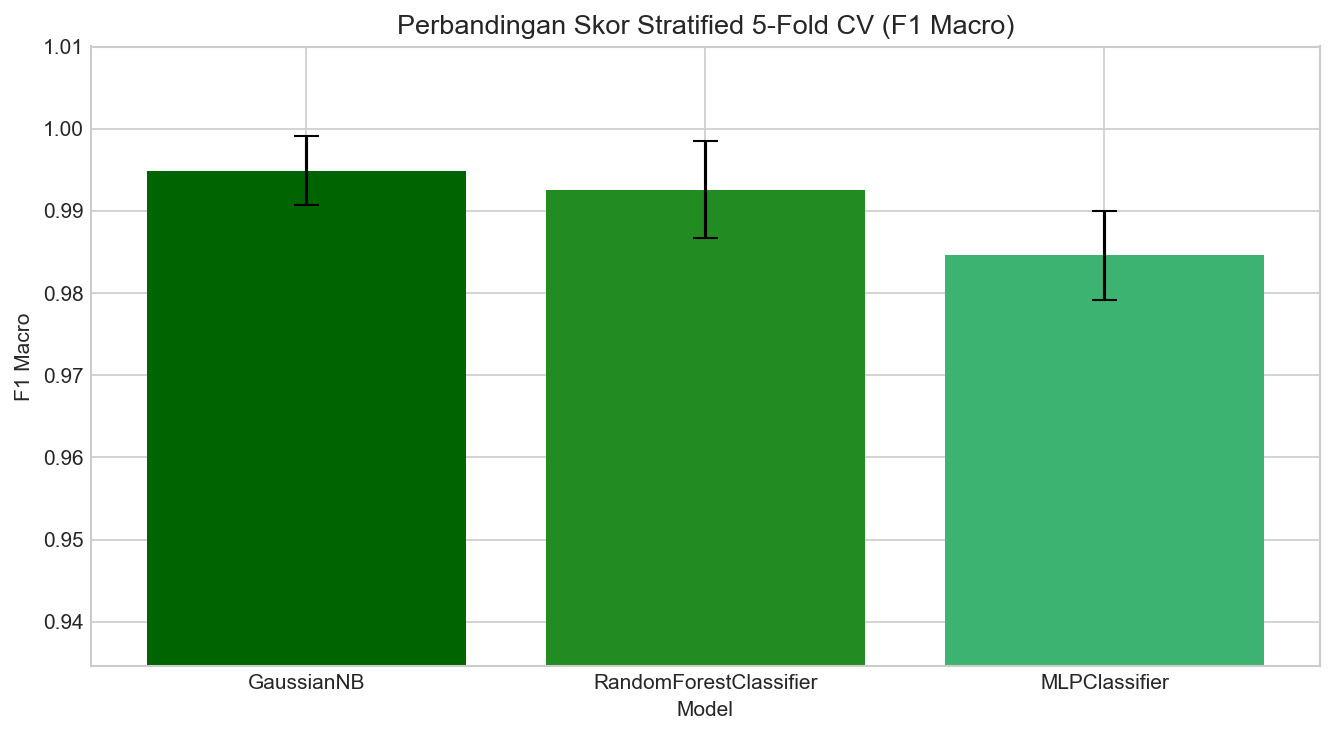

[EVAL_PLOT] chart=cv_comparison | saved=artifacts/plots/eval/eval_cv_comparison.png


In [6]:
def plot_cv_comparison(res: ExperimentResult, cfg: ExperimentConfig) -> Path:
    df_plot = res.comparison_df
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
        ax.bar(
            df_plot["model"],
            df_plot["cv_f1_macro_mean"],
            yerr=df_plot["cv_f1_macro_std"],
            capsize=6,
            color=["darkgreen", "forestgreen", "mediumseagreen"][: len(df_plot)],
        )
        ax.set_ylim(max(0.0, float(df_plot["cv_f1_macro_mean"].min()) - 0.05), 1.01)
        ax.set_title("Perbandingan Skor Stratified 5-Fold CV (F1 Macro)", fontsize=13)
        ax.set_ylabel("F1 Macro")
        ax.set_xlabel("Model")
        plt.tight_layout()
        output_path = cfg.plots_dir / "eval_cv_comparison.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EVAL_PLOT", chart="cv_comparison", saved=output_path.as_posix())
    return output_path


_ = plot_cv_comparison(result, config)

### **5.2 Confusion Matrix Test Set**

Menampilkan jumlah prediksi benar serta kelas tanaman yang masih tertukar pada *test set*.

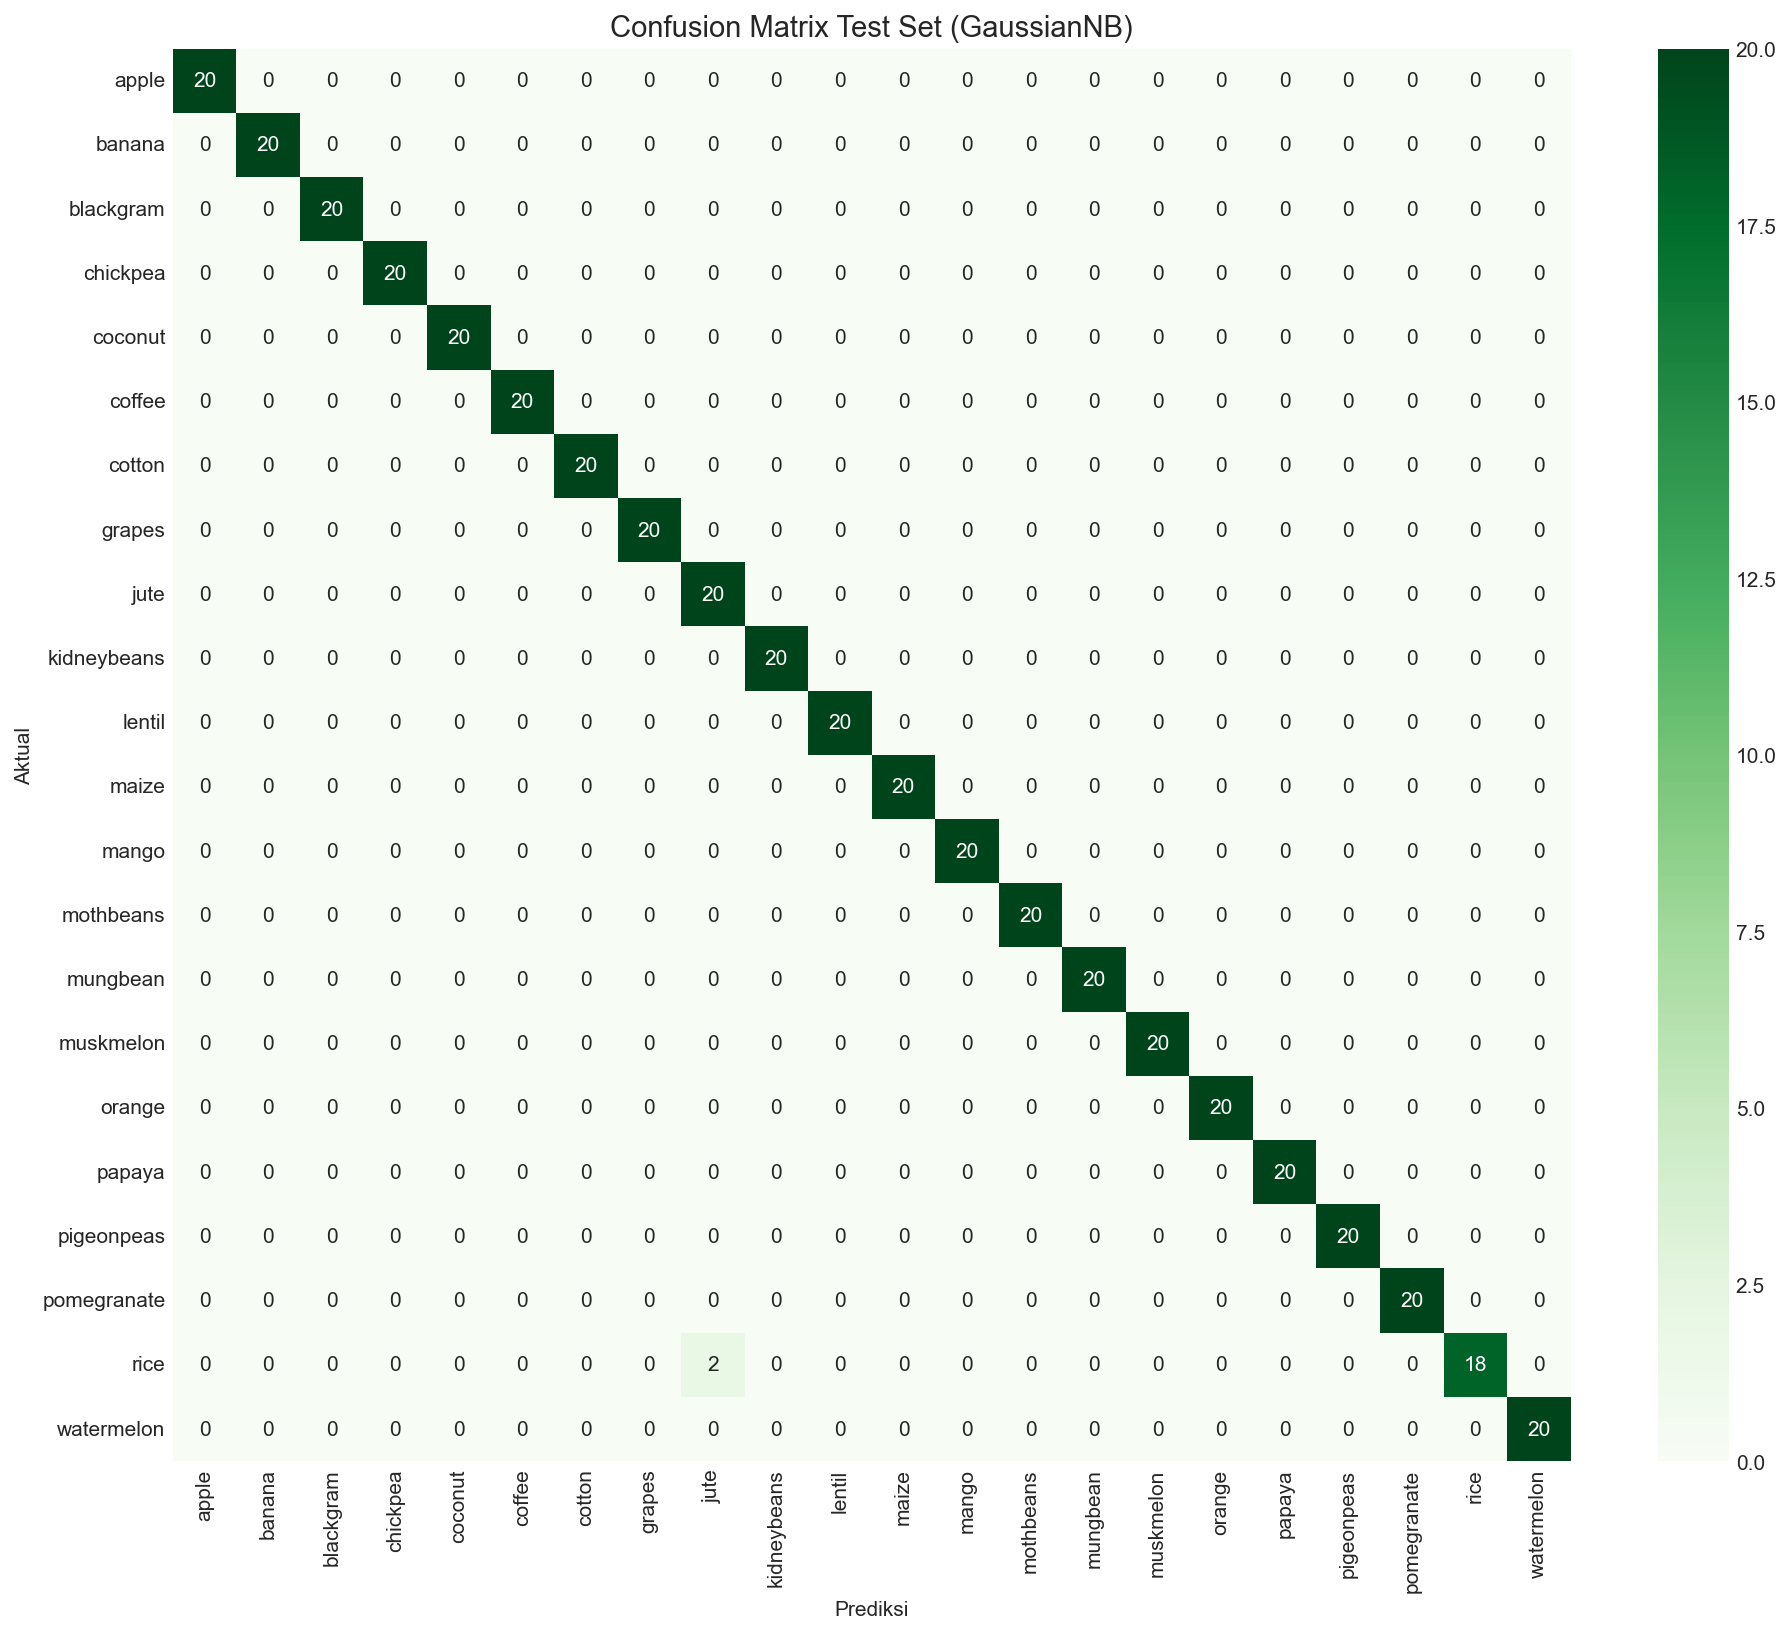

[EVAL_PLOT] chart=confusion_matrix | saved=artifacts/plots/eval/eval_confusion_matrix.png


In [7]:
def plot_confusion_matrix(res: ExperimentResult, cfg: ExperimentConfig) -> Path:
    labels = sorted(res.y_test.unique().tolist())
    cm = confusion_matrix(res.y_test, res.y_pred, labels=labels)
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, ax = plt.subplots(figsize=(13, 11), dpi=150)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels, ax=ax)
        ax.set_title(f"Confusion Matrix Test Set ({res.winner_name})", fontsize=14)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
        plt.tight_layout()
        output_path = cfg.plots_dir / "eval_confusion_matrix.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EVAL_PLOT", chart="confusion_matrix", saved=output_path.as_posix())
    return output_path


_ = plot_confusion_matrix(result, config)

### **5.3 Feature Importance**

Mengukur kontribusi relatif tiap fitur pada model berbasis *tree* (dilewati otomatis bila model terpilih tidak menyediakan atribut `feature_importances_`).

In [8]:
def plot_feature_importance(res: ExperimentResult, cfg: ExperimentConfig) -> Path | None:
    classifier = res.winner_pipeline.named_steps["classifier"]
    if not hasattr(classifier, "feature_importances_"):
        log_event("EVAL_PLOT", chart="feature_importance", status="SKIPPED", reason="NO_ATTRIBUTE")
        return None

    importances = pd.Series(classifier.feature_importances_, index=cfg.feature_columns).sort_values()
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
        importances.plot(kind="barh", ax=ax, color="forestgreen")
        ax.set_title(f"Feature Importance ({res.winner_name})", fontsize=13)
        ax.set_xlabel("Importance Score")
        ax.set_ylabel("Fitur")
        plt.tight_layout()
        output_path = cfg.plots_dir / "eval_feature_importance.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EVAL_PLOT", chart="feature_importance", saved=output_path.as_posix())
    return output_path


_ = plot_feature_importance(result, config)

[EVAL_PLOT] chart=feature_importance | status=SKIPPED | reason=NO_ATTRIBUTE


## **6. Penyimpanan Artifact Model**

Melatih ulang *pipeline* model terpilih pada seluruh dataset sebelum menyimpan `model_pipeline.joblib` dan `metadata.json` ke `artifacts/`.

In [9]:
def export_artifacts(cfg: ExperimentConfig, res: ExperimentResult) -> tuple[Path, Path]:
    winner_params = cfg.models_cfg[res.winner_name].get("params", {})
    production_pipeline = build_pipeline(res.winner_name, winner_params)
    production_pipeline.fit(res.X_full, res.y_full)

    joblib.dump(production_pipeline, cfg.model_path)

    feature_ranges = {
        col: {
            "min": round(float(res.X_full[col].min()), 4),
            "max": round(float(res.X_full[col].max()), 4),
            "mean": round(float(res.X_full[col].mean()), 4),
        }
        for col in cfg.feature_columns
    }

    metadata = {
        "model_name": res.winner_name,
        "artifact_version": cfg.version,
        "trained_at": datetime.now(timezone.utc).isoformat(),
        "features": cfg.feature_columns,
        "classes": sorted(res.y_full.unique().tolist()),
        "metrics": {
            "cv_mean": round(res.winner_cv_metrics["cv_mean"], 5),
            "cv_std": round(res.winner_cv_metrics["cv_std"], 5),
            "test_accuracy": round(res.test_accuracy, 5),
            "test_f1_macro": round(res.test_f1_macro, 5),
        },
        "feature_ranges": feature_ranges,
    }

    with cfg.metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2)

    log_event(
        "EXPORT",
        status="SUCCESS",
        model_file=cfg.model_path.name,
        metadata_file=cfg.metadata_path.name,
        classes=len(metadata["classes"]),
    )
    return cfg.model_path, cfg.metadata_path


saved_model_path, saved_metadata_path = export_artifacts(config, result)

[EXPORT] status=SUCCESS | model_file=model_pipeline.joblib | metadata_file=metadata.json | classes=22


## **7. Kesimpulan Eksperimen**

`GaussianNB` terpilih sebagai model final dengan skor Stratified 5-Fold CV tertinggi (`f1_macro` `0.9949`, `std = 0.0042`), mengungguli `RandomForestClassifier` (`0.9926`) dan `MLPClassifier` (`0.9846`), serta meraih `test_accuracy` `0.9955` dan `test_f1_macro` `0.9954` pada 440 sampel uji (hanya 2 sampel `rice` terprediksi sebagai `jute` karena kemiripan profil iklim dan nutrisinya).

Hasil ini menunjukkan distribusi fitur per kelas sudah cukup terpisah untuk model Gaussian tanpa memerlukan kompleksitas *ensemble* atau jaringan saraf. Untuk pengujian lanjutan, perlu ditambahkan *permutation importance* (karena `GaussianNB` tidak memiliki `feature_importances_`) serta validasi data dengan *noise* pengukuran lapangan.